In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from tqdm import tqdm

from utils.complex_param import complex_param_perturbated, de_phase_solution
from utils.fourth_order_runge_kuta import rk_interval
from utils.model import cosine_kernel_fft, kuramoto_kernel, vf_r_theta
from utils.plotting_utils import generate_yticks_and_labels
from utils.self_consistency import self_consistency_rewrite_root

BASE_FOLDER = Path("./paper_plots")
BASE_FOLDER.mkdir(parents=True, exist_ok=True)

In [2]:
N = 1024
A = 0.995
alpha = (np.pi / 2) - 0.16
kernel_fft = cosine_kernel_fft(A, N)

omegas = np.zeros(N)

np.random.seed(seed=1338)
cosine_amplitude = 0.01

evolve_time = 1000.0
dt = 0.1

x = np.linspace(-np.pi, np.pi, N, endpoint=False)
beta_positions = [np.pi / 2, np.pi]
beta_positions_in_points = [
    int(N * (beta_position + np.pi) / (2 * np.pi)) - 1
    for beta_position in beta_positions
]

In [3]:
initial_conditions = (
    6.0
    * np.exp(-0.76 * (np.linspace(-np.pi, np.pi, N, endpoint=False)) ** 2)
    * (np.random.random(N) - 0.5)
)

# INITIAL EVOLUTION NO SAVING TIME AUTOMATIC


In [4]:
kuramoto = kuramoto_kernel(omegas, kernel_fft, alpha=alpha)
t_evolve_eval = np.arange(0, evolve_time + dt, dt)
t_evolve_span = (0, evolve_time + dt)
sol = solve_ivp(
    lambda _, y: kuramoto(y),
    t_evolve_span,
    initial_conditions,
    t_eval=t_evolve_eval,
    method="RK45",
    rtol=1e-7,
    atol=1e-10,
)
init_state = sol.y.T

In [5]:
solutions = []

for beta_position in tqdm(beta_positions):
    new_omegas = omegas.copy() + cosine_amplitude * np.cos(x + beta_position)
    kuramoto = kuramoto_kernel(new_omegas, kernel_fft, alpha=alpha)
    t_evolve_eval = np.arange(0, evolve_time * 4 + dt, dt)
    t_evolve_span = (0, evolve_time * 4 + dt)
    sol = solve_ivp(
        lambda t, y: kuramoto(y),
        t_evolve_span,
        init_state[-1],
        t_eval=t_evolve_eval,
        method="RK45",
        rtol=1e-7,
        atol=1e-10,
    )
    solutions.append(sol)

100%|██████████| 2/2 [00:05<00:00,  2.76s/it]


<Figure size 1800x1560 with 0 Axes>

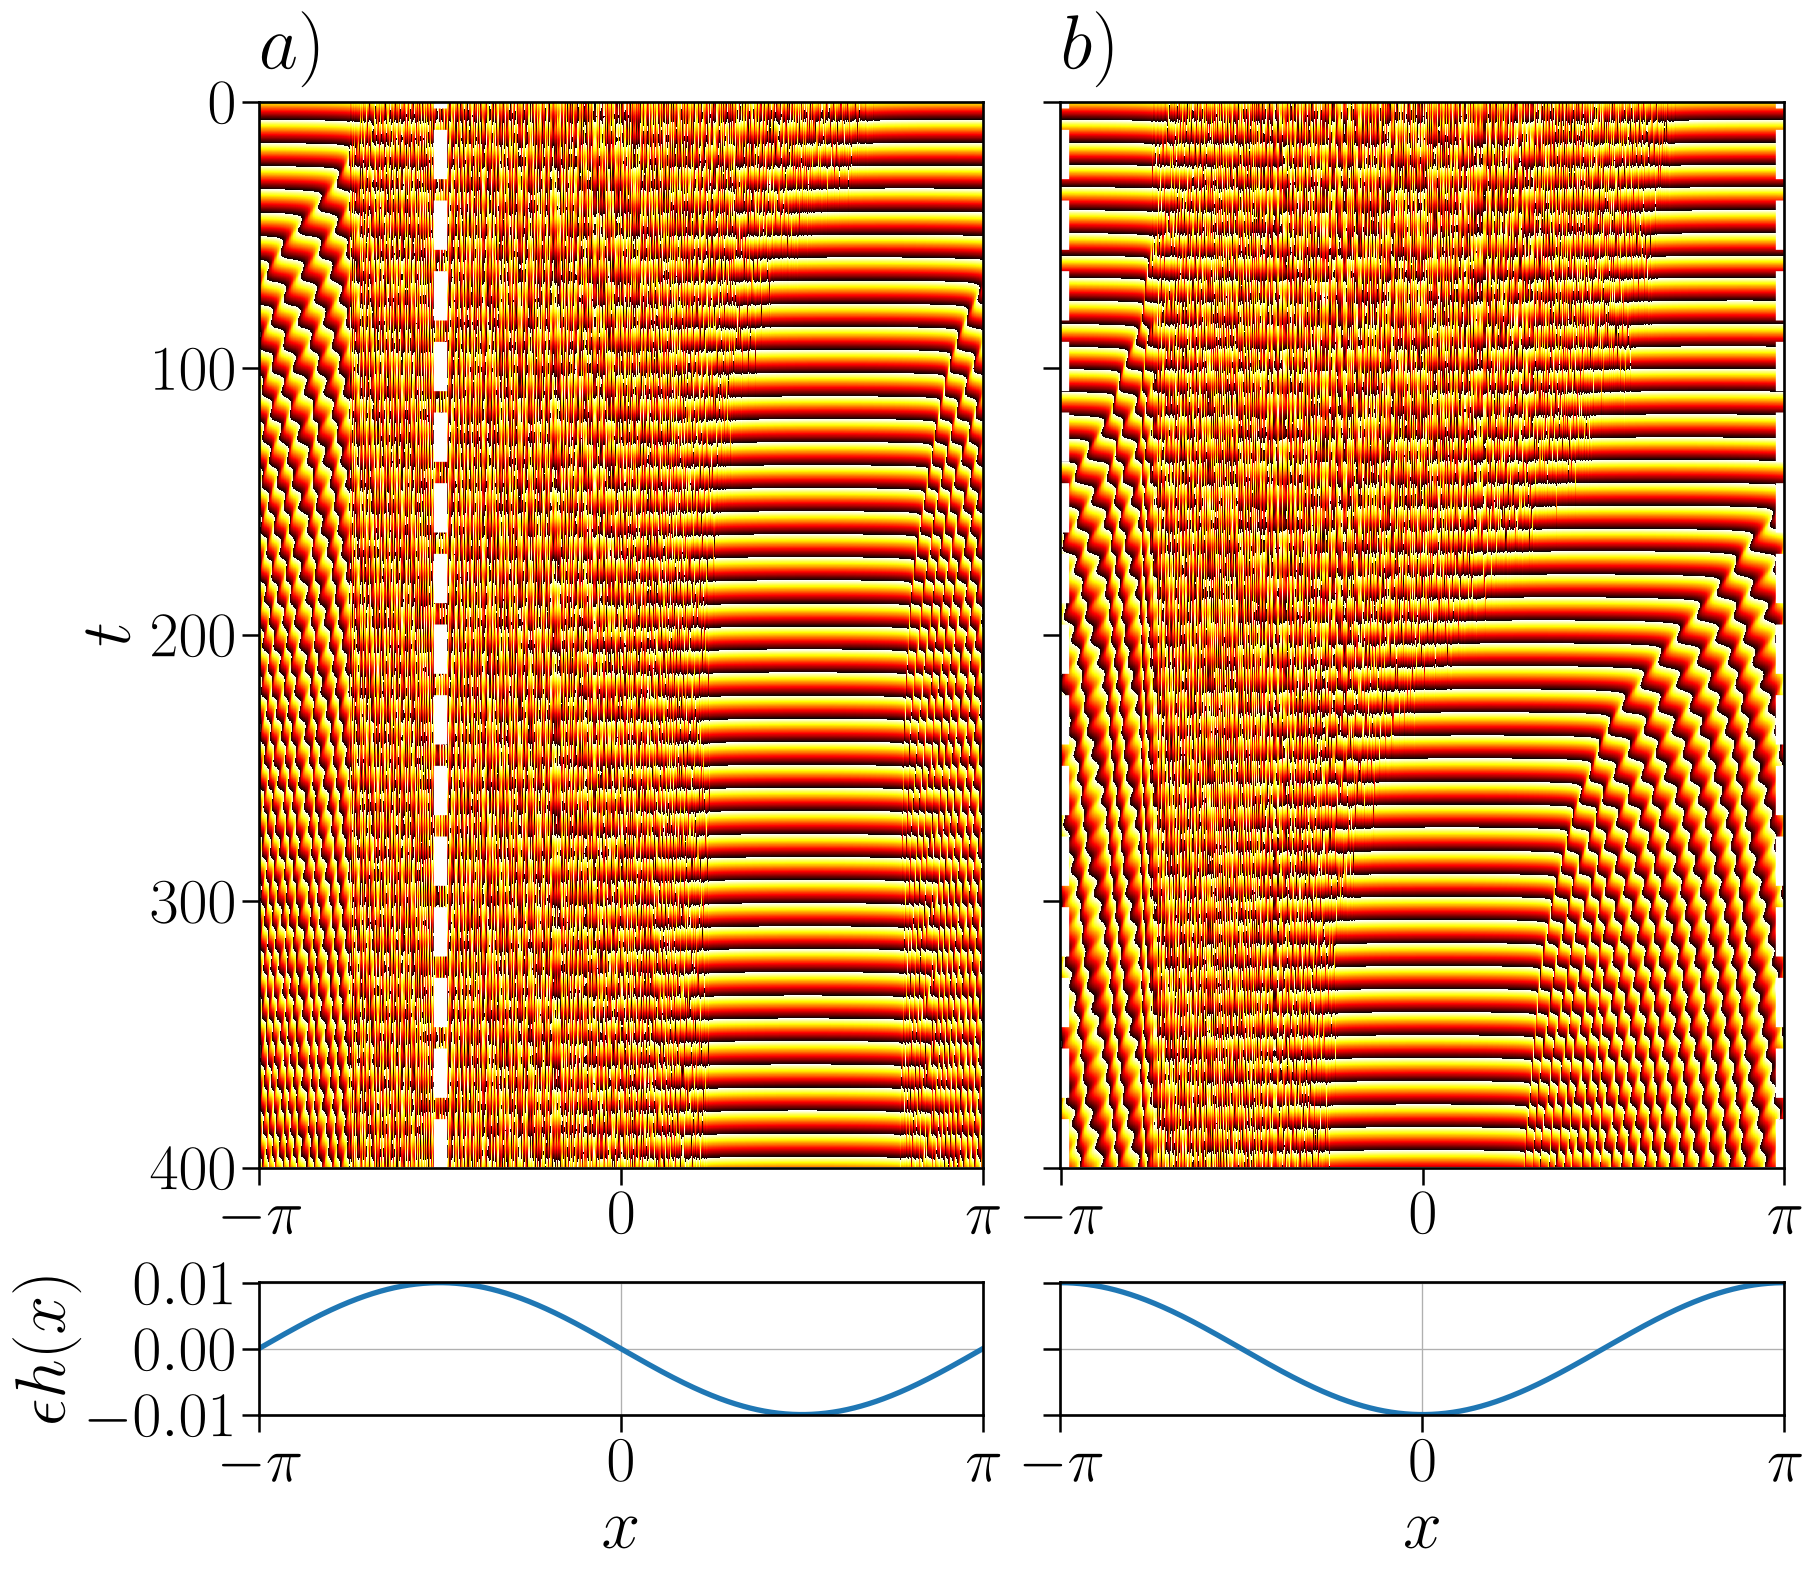

In [6]:
plt.figure()
titles = [r"$a)$", r"$b)$"]
fig, axes = plt.subplots(
    2, 2, gridspec_kw={"height_ratios": [8, 1]}, layout="constrained", sharey="row"
)
for i, sol in enumerate(solutions):
    evolve_time = sol.t[:4000][-1]
    state = sol.y.T[:4000]
    forcing_location = beta_positions[i]
    yticks, ytick_labels = generate_yticks_and_labels(sol, evolve_time)

    heatmap = axes[0, i].imshow(
        state % (2 * np.pi), aspect="auto", interpolation="none", cmap="hot"
    )

    axes[0, i].set_yticks(yticks)
    axes[0, i].set_yticklabels(ytick_labels)
    # axes[0, i].set_xlabel(r"$x$")
    axes[0, i].set_title(titles[i], loc="left")

    axes[0, i].set_xticks([0, N / 2, N - 1])
    axes[0, i].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

    sine = cosine_amplitude * np.cos(x + forcing_location)
    axes[1, i].plot(x, sine)
    axes[1, i].set_xlabel(r"$x$")
    axes[1, i].grid(True)

    axes[1, i].set_xticks([-np.pi, 0, np.pi])
    axes[1, i].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])
    axes[1, i].set_xlim([-np.pi, np.pi])
    axes[1, i].set_ylim([-cosine_amplitude - 0.0001, cosine_amplitude + 0.0001])

    if i == 0:
        axes[0, i].set_ylabel(r"$t$")
        axes[1, i].set_ylabel(r"$\epsilon h(x)$", labelpad=1)

    if i == 0:
        axes[0, i].axvline(x=N // 4, color="white", linestyle="--", linewidth=8)
    if i == 1:
        axes[0, i].axvline(x=2, color="white", linestyle="--", linewidth=8)
        axes[0, i].axvline(x=N - 4, color="white", linestyle="--", linewidth=8)


# fig.tight_layout(rect=[0, 0, 1, 1])  # Leave space for the shared x-label

plt.show()

True A solution was found at the specified tolerance.  message: A solution was found at the specified tolerance.
 success: True
  status: 1
     fun: [-2.124e-07 -3.095e-07 ... -5.042e-07 -1.517e-08]
       x: [ 5.959e-01  5.947e-01 ...  7.670e-02 -7.272e-01]
     nit: 184
  method: krylov
    nfev: 3189
True A solution was found at the specified tolerance.  message: A solution was found at the specified tolerance.
 success: True
  status: 1
     fun: [ 3.077e-08  1.553e-08 ... -5.194e-09  5.482e-13]
       x: [ 4.076e-01  4.076e-01 ...  1.492e-01 -7.272e-01]
     nit: 98
  method: krylov
    nfev: 1604


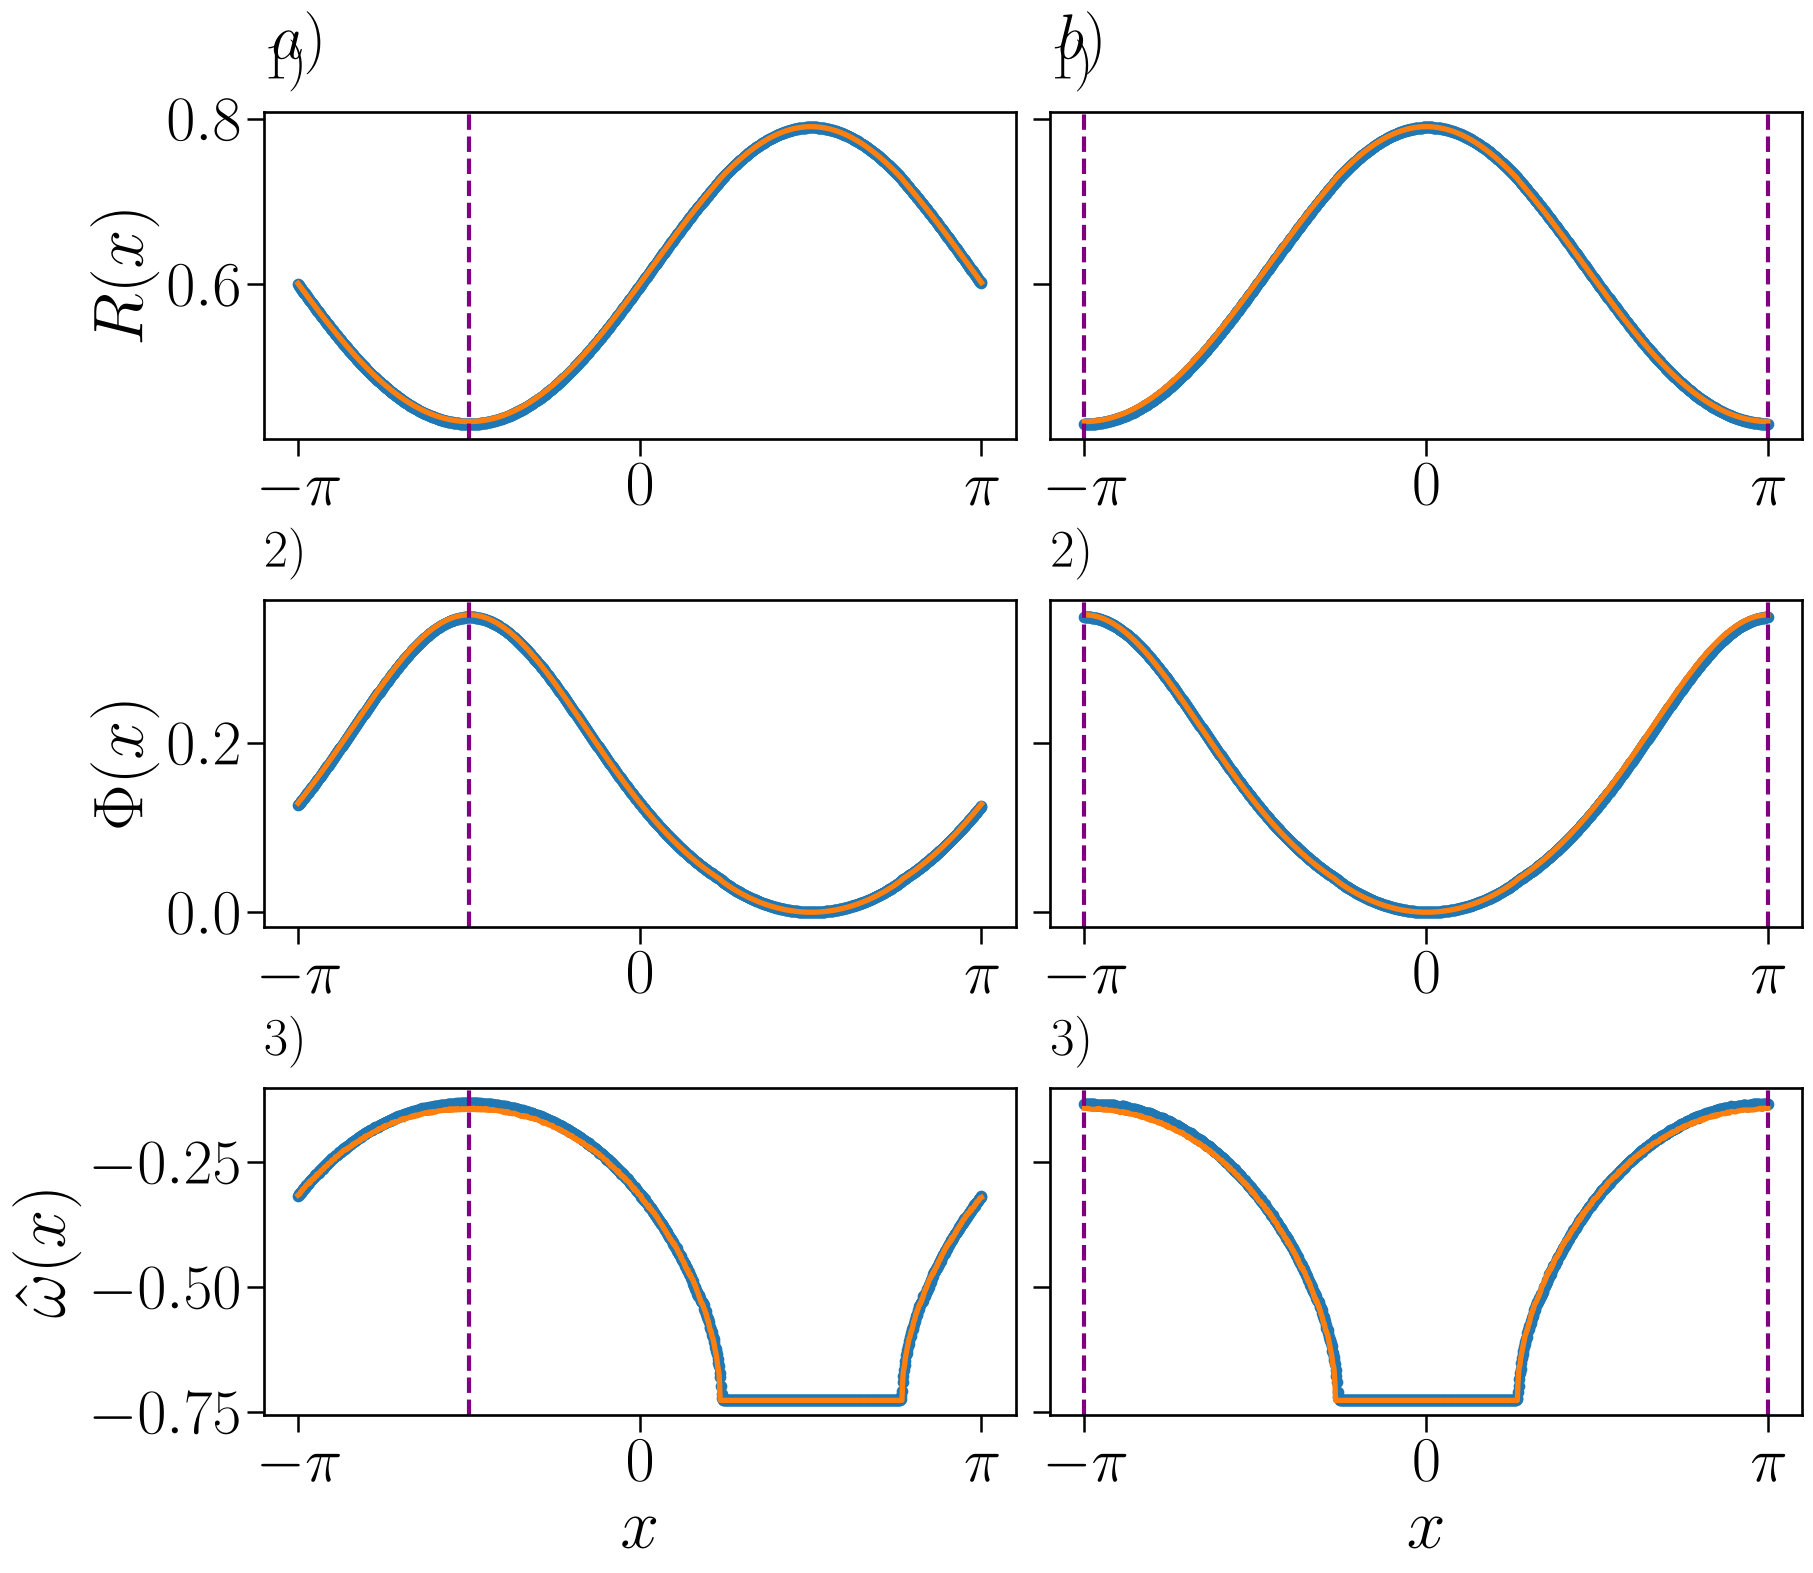

In [7]:
fig, axs = plt.subplots(3, 2, constrained_layout=True, sharey="row")
titles = [r"$a)$", r"$b)$", r"$c)$", r"$d)$"]

big_omegas = []
for i, ax_col in enumerate(axs.T):  # Loop over columns
    # Subplot title for each column
    ax_col[0].set_title(titles[i], loc="left", fontsize="large")
    ax_col[0].text(-40, 0.93, titles[i], verticalalignment="top", rotation=0)

    sol = solutions[i]
    epsh_func = cosine_amplitude * np.cos(x + beta_positions[i])
    init_state = sol.y.T[-30000:]

    z = complex_param_perturbated(kernel_fft, init_state, epsh_func, alpha)

    r_orig = np.mean(np.abs(z), axis=0)
    theta_orig = np.unwrap(np.unwrap(np.angle(z), axis=0).mean(axis=0))
    theta_orig = theta_orig - np.min(theta_orig)

    unwrap_state = np.unwrap(init_state, axis=0)
    omega_real = (np.diff(unwrap_state, axis=0)).mean(axis=0) / dt

    r_sol, theta_sol, Omega, root_result = self_consistency_rewrite_root(
        r_orig,
        theta_orig,
        np.min(omega_real),
        kernel_fft,
        0.0,
        epsh_func,
        alpha,
        options={},
    )
    print(root_result.success, root_result.message, root_result)
    big_omegas.append(Omega)

    new_initial_conditions = init_state[-1] % (2 * np.pi)
    model = vf_r_theta(omegas, Omega, r_sol, theta_sol, alpha)
    dt = 0.1
    sim_state = rk_interval(new_initial_conditions, model, 1000.0, dt)
    sim_state = sim_state[1000:, :]

    state_sim = np.unwrap(sim_state, axis=0)
    omega_sim = (np.diff(state_sim, axis=0)).mean(axis=0) / dt

    # Subplots for r(x), theta(x), and omega(x)
    ax_col[0].scatter(np.arange(N), r_orig)
    ax_col[0].plot(np.arange(N), r_sol, c="tab:orange")
    ax_col[0].set_title(r"$1)$", fontsize="small", loc="left")
    ax_col[0].set_xticks([0, N / 2, N - 1])
    ax_col[0].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

    ax_col[1].scatter(np.arange(N), theta_orig)
    ax_col[1].plot(np.arange(N), theta_sol, c="tab:orange")
    ax_col[1].set_title(r"$2)$", fontsize="small", loc="left")
    ax_col[1].set_xticks([0, N / 2, N - 1])
    ax_col[1].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

    ax_col[2].scatter(np.arange(N), omega_real)
    ax_col[2].plot(np.arange(N), omega_sim + Omega, c="tab:orange")
    ax_col[2].set_xlabel(r"$x$")
    ax_col[2].set_title(r"$3)$", fontsize="small", loc="left")
    ax_col[2].set_xticks([0, N / 2, N - 1])
    ax_col[2].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

    if i == 0:
        ax_col[0].axvline(x=N // 4, color="purple", linestyle="--", linewidth=2.5)
        ax_col[1].axvline(x=N // 4, color="purple", linestyle="--", linewidth=2.5)
        ax_col[2].axvline(x=N // 4, color="purple", linestyle="--", linewidth=2.5)

    if i == 1:
        ax_col[0].axvline(x=0, color="purple", linestyle="--", linewidth=2.5)
        ax_col[1].axvline(x=0, color="purple", linestyle="--", linewidth=2.5)
        ax_col[2].axvline(x=0, color="purple", linestyle="--", linewidth=2.5)

        ax_col[0].axvline(x=N, color="purple", linestyle="--", linewidth=2.5)
        ax_col[1].axvline(x=N, color="purple", linestyle="--", linewidth=2.5)
        ax_col[2].axvline(x=N, color="purple", linestyle="--", linewidth=2.5)

    # TO GO TO THE ORIGINAL PLOT REMOVE THE IF STATEMENT AND REMOVE sharey
    if i == 0:
        ax_col[0].set_ylabel(r"$R(x)$")
        ax_col[1].set_ylabel(r"$\Phi(x)$")
        ax_col[2].set_ylabel(r"$\hat{\omega}(x)$")


plt.savefig(BASE_FOLDER / "6.pdf")
plt.show()

<Figure size 1800x1560 with 0 Axes>

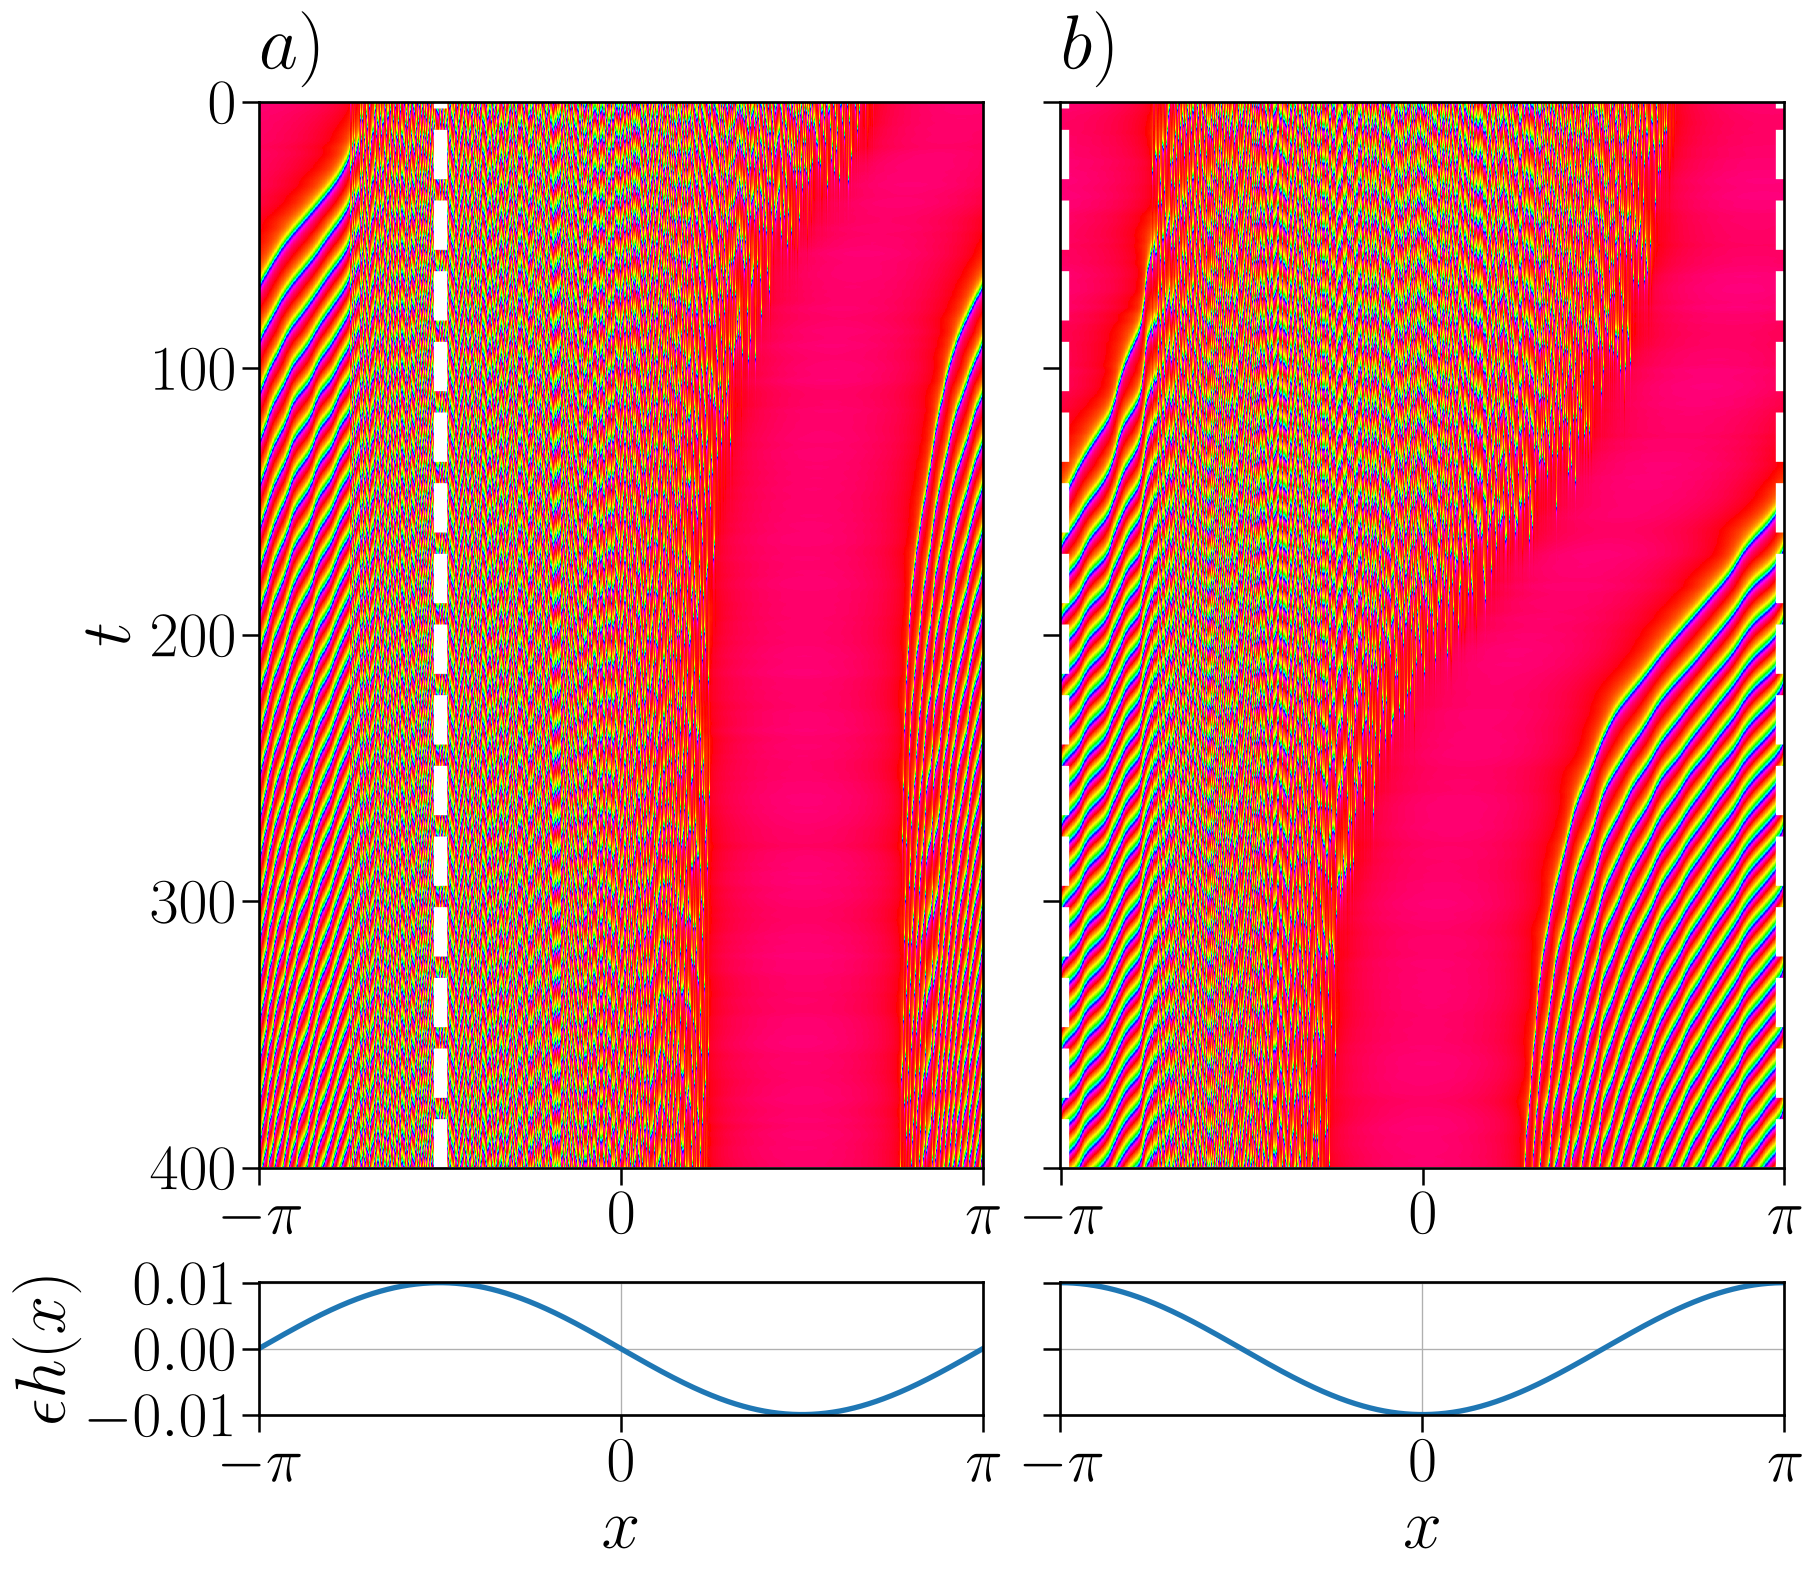

In [8]:
plt.figure()
titles = [r"$a)$", r"$b)$"]
fig, axes = plt.subplots(
    2, 2, gridspec_kw={"height_ratios": [8, 1]}, layout="constrained", sharey="row"
)
for i, sol in enumerate(solutions):
    evolve_time = sol.t[:4000][-1]
    state = sol.y.T[:4000]
    forcing_location = beta_positions[i]
    yticks, ytick_labels = generate_yticks_and_labels(sol, evolve_time)

    constant_phase = de_phase_solution(state)

    if i == 0:
        constant_phase = constant_phase - constant_phase[-1, -N // 4]
    if i == 1:
        constant_phase = constant_phase - constant_phase[-1, N // 2]

    heatmap = axes[0, i].imshow(
        constant_phase, aspect="auto", interpolation="none", cmap="hsv"
    )

    axes[0, i].set_yticks(yticks)
    axes[0, i].set_yticklabels(ytick_labels)
    # axes[0, i].set_xlabel(r"$x$")
    axes[0, i].set_title(titles[i], loc="left")

    axes[0, i].set_xticks([0, N / 2, N - 1])
    axes[0, i].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

    sine = cosine_amplitude * np.cos(x + forcing_location)
    axes[1, i].plot(x, sine)
    axes[1, i].set_xlabel(r"$x$")
    axes[1, i].grid(True)

    axes[1, i].set_xticks([-np.pi, 0, np.pi])
    axes[1, i].set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])
    axes[1, i].set_xlim([-np.pi, np.pi])
    axes[1, i].set_ylim([-cosine_amplitude - 0.0001, cosine_amplitude + 0.0001])

    if i == 0:
        axes[0, i].set_ylabel(r"$t$")
        axes[1, i].set_ylabel(r"$\epsilon h(x)$", labelpad=1)

    if i == 0:
        axes[0, i].axvline(x=N // 4, color="white", linestyle="--", linewidth=8)
    if i == 1:
        axes[0, i].axvline(x=2, color="white", linestyle="--", linewidth=8)
        axes[0, i].axvline(x=N - 4, color="white", linestyle="--", linewidth=8)


# fig.tight_layout(rect=[0, 0, 1, 1])  # Leave space for the shared x-label


plt.savefig(BASE_FOLDER / "3.pdf")
plt.show()